In [2]:
!pip install -q kagglehub

import kagglehub
import pandas as pd
import os

path = kagglehub.dataset_download(
    "atharvaingle/crop-recommendation-dataset"
)

print("Downloaded to:", path)
print("Files:", os.listdir(path))

df = pd.read_csv(
    os.path.join(path, "Crop_recommendation.csv")
)

print("Dataset shape:", df.shape)
display(df.head())

100%|██████████| 63.7k/63.7k [00:00<00:00, 643kB/s]

Extracting files...
Downloaded to: /root/.cache/kagglehub/datasets/atharvaingle/crop-recommendation-dataset/versions/1
Files: ['Crop_recommendation.csv']
Dataset shape: (2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [3]:
print(df.columns.tolist())


['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']


In [4]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


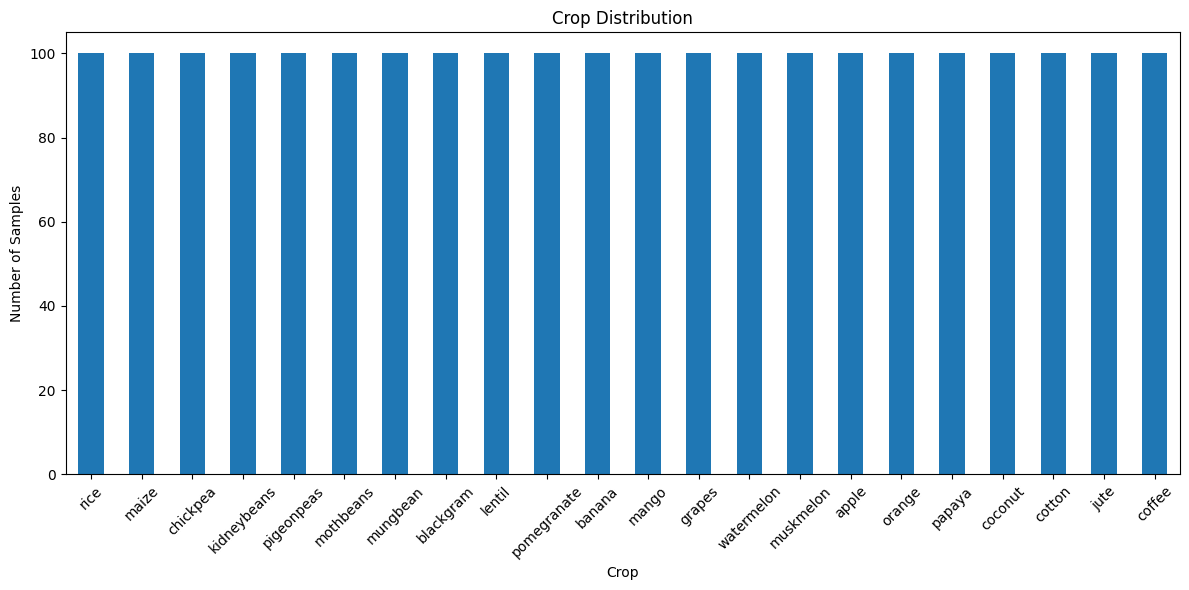

In [5]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))

df["label"].value_counts().plot(kind="bar")

plt.title("Crop Distribution")
plt.xlabel("Crop")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [6]:
features = [
    "N",
    "P",
    "K",
    "temperature",
    "humidity",
    "ph",
    "rainfall"
]

df[features].describe().T

,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.551818,36.917334,0.000000,21.000000,37.000000,84.250000,140.000000
P,2200.0,53.362727,32.985883,5.000000,28.000000,51.000000,68.000000,145.000000
K,2200.0,48.149091,50.647931,5.000000,20.000000,32.000000,49.000000,205.000000
temperature,2200.0,25.616244,5.063749,8.825675,22.769375,25.598693,28.561654,43.675493
humidity,2200.0,71.481779,22.263812,14.258040,60.261953,80.473146,89.948771,99.981876
ph,2200.0,6.469480,0.773938,3.504752,5.971693,6.425045,6.923643,9.935091
rainfall,2200.0,103.463655,54.958389,20.211267,64.551686,94.867624,124.267508,298.560117


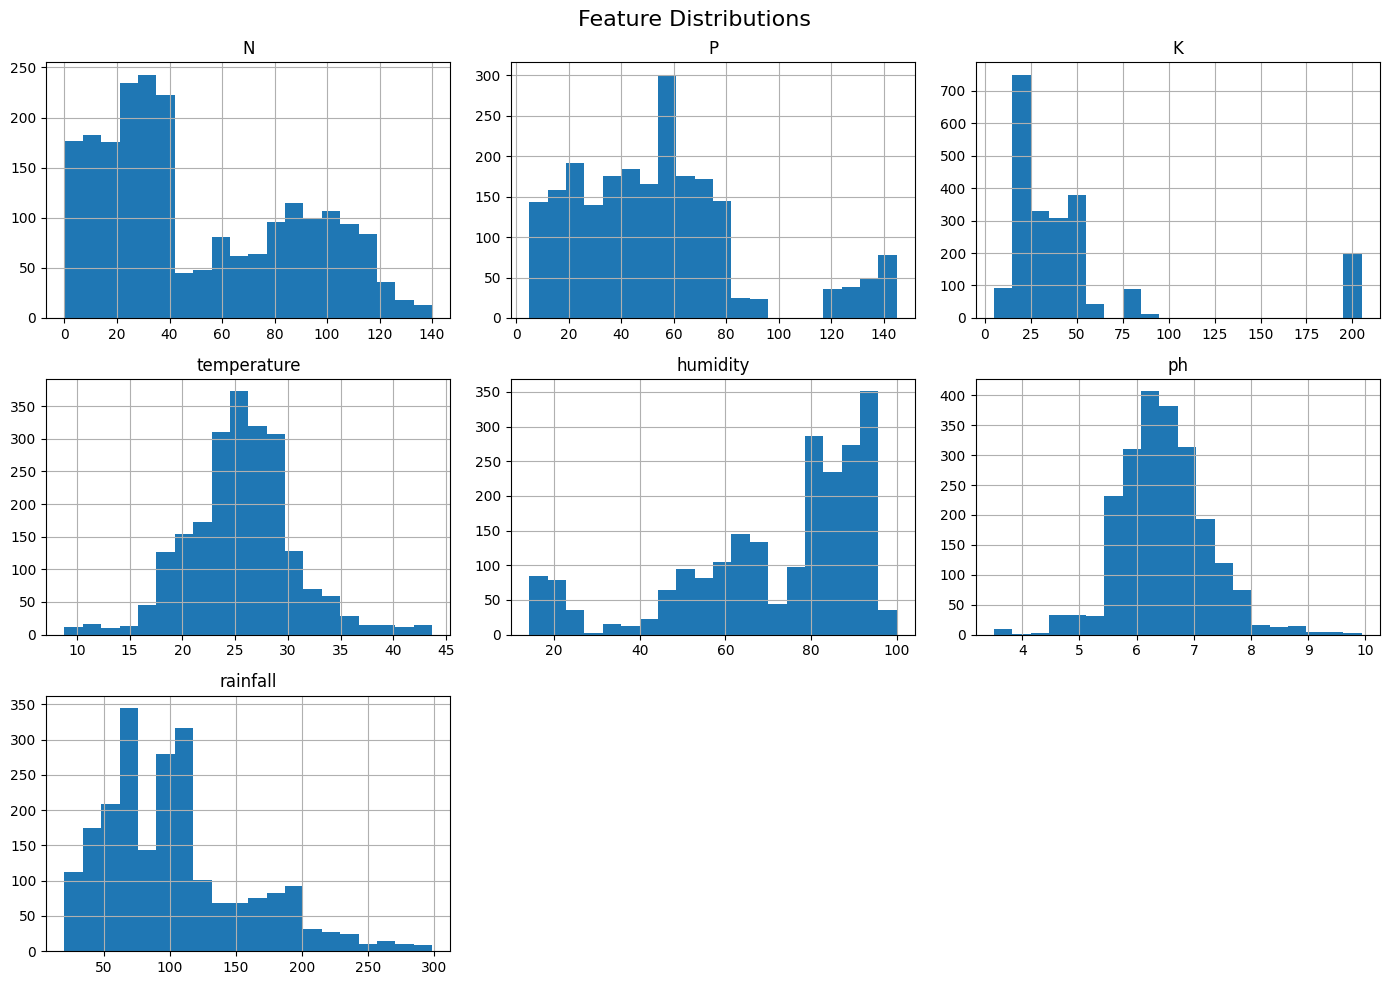

In [7]:
df[features].hist(
    figsize=(14, 10),
    bins=20
)

plt.suptitle("Feature Distributions", fontsize=16)
plt.tight_layout()
plt.show()

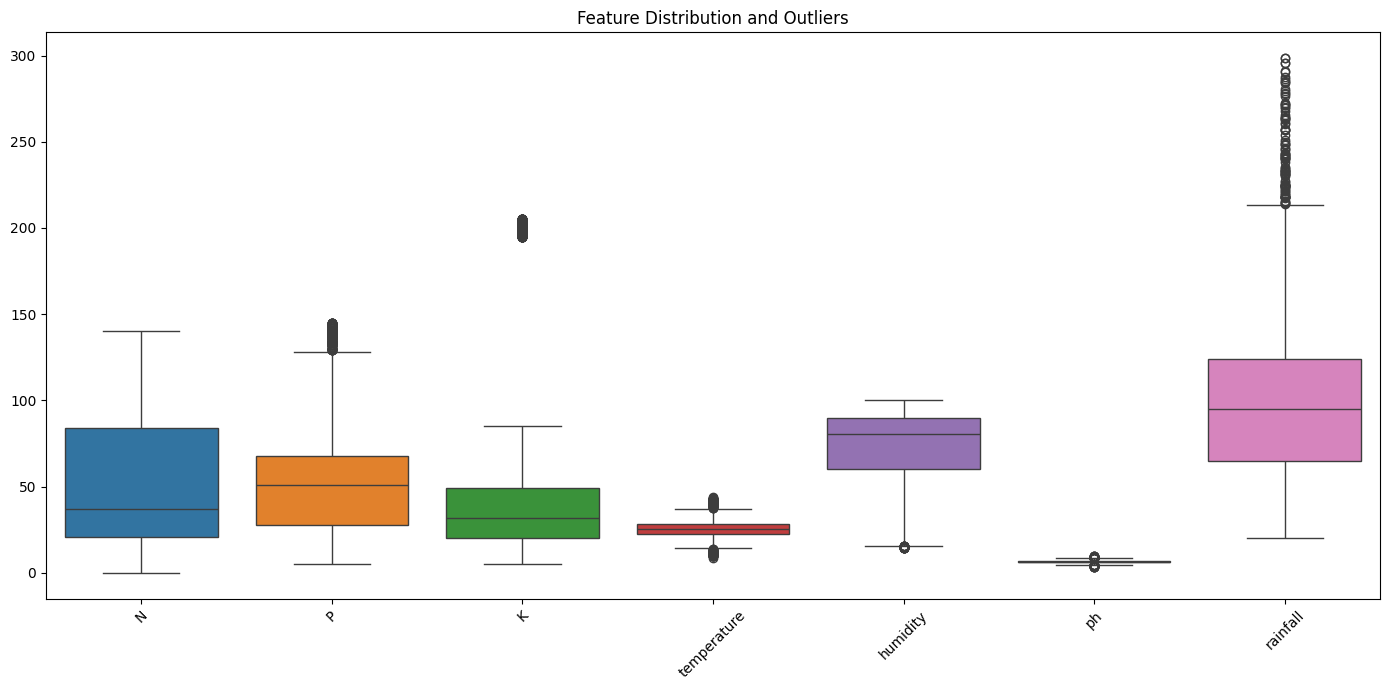

In [8]:
import seaborn as sns
plt.figure(figsize=(14, 7))

sns.boxplot(data=df[features])

plt.title("Feature Distribution and Outliers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
print("Duplicate rows:", df.duplicated().sum())
print("Missing values:")
print(df[features + ["label"]].isnull().sum())

Duplicate rows: 0
Missing values:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64


In [10]:
features = [
    "N",
    "P",
    "K",
    "temperature",
    "humidity",
    "ph",
    "rainfall"
]

X = df[features]
y = df["label"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (2200, 7)
y shape: (2200,)


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 1760
Testing samples: 440


In [13]:
# model

models = {

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            C=10,
            gamma="scale"
        ))
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5
        ))
    ])
}


# Trainimg

results = []

trained_models = {}

for name, model in models.items():

    print("\nTraining:", name)

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    trained_models[name] = model

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="weighted"
        ),
        "Recall": recall_score(
            y_test, y_pred, average="weighted"
        ),
        "F1 Score": f1_score(
            y_test, y_pred, average="weighted"
        )
    })

results_df = pd.DataFrame(results)

print("\nModel Comparison:")
display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)


Training: Random Forest

Training: SVM

Training: KNN

Model Comparison:


,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.9955,0.9957,0.9955,0.9955
1,SVM,0.9886,0.9896,0.9886,0.9887
2,KNN,0.9795,0.9804,0.9795,0.9793


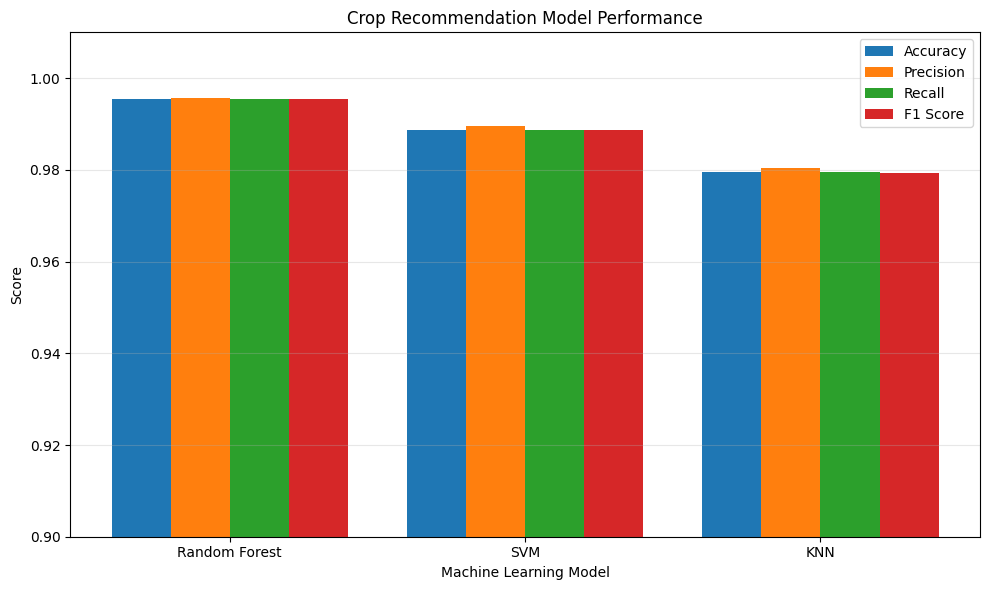

In [15]:

# MODEL PERFORMANCE COMPARISON


plt.figure(figsize=(10, 6))

metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

x = np.arange(len(results_df["Model"]))
width = 0.2

for i, metric in enumerate(metrics):
    plt.bar(
        x + (i - 1.5) * width,
        results_df[metric],
        width,
        label=metric
    )

plt.xticks(
    x,
    results_df["Model"]
)

plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.title("Crop Recommendation Model Performance")

# Zoom into the relevant range
plt.ylim(0.90, 1.01)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [17]:
# ============================================
# STEP 1: CHECK DATASET FOR DUPLICATES
# ============================================

print("Dataset shape:", df.shape)

print("\nExact duplicate rows:")
print(df.duplicated().sum())

print("\nDuplicate feature combinations:")
print(df.duplicated(subset=features).sum())

print("\nSamples per crop:")
print(df["label"].value_counts().sort_index())

print("\nMissing values:")
print(df.isnull().sum())

print("\nFeatures used:")
print(features)

print("\nTarget:")
print("label")

Dataset shape: (2200, 8)

Exact duplicate rows:
0

Duplicate feature combinations:
0

Samples per crop:
label
apple          100
banana         100
blackgram      100
chickpea       100
coconut        100
coffee         100
cotton         100
grapes         100
jute           100
kidneybeans    100
lentil         100
maize          100
mango          100
mothbeans      100
mungbean       100
muskmelon      100
orange         100
papaya         100
pigeonpeas     100
pomegranate    100
rice           100
watermelon     100
Name: count, dtype: int64

Missing values:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Features used:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

Target:
label


In [18]:
# ============================================
# STEP 2: 5-FOLD CROSS VALIDATION
# ============================================

from sklearn.model_selection import StratifiedKFold, cross_validate

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "precision": "precision_weighted",
    "recall": "recall_weighted",
    "f1": "f1_weighted"
}

cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),

        "Accuracy Std": scores["test_accuracy"].std(),
        "F1 Std": scores["test_f1"].std()
    })


# Convert to DataFrame
cv_df = pd.DataFrame(cv_results)

# Display results
print("5-Fold Cross-Validation Results\n")

display(
    cv_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "Accuracy Std": "{:.4f}",
        "F1 Std": "{:.4f}"
    })
)

5-Fold Cross-Validation Results



,Model,Accuracy,Precision,Recall,F1 Score,Accuracy Std,F1 Std
0,Random Forest,0.9959,0.9962,0.9959,0.9959,0.0027,0.0027
1,SVM,0.9882,0.9891,0.9882,0.9881,0.0036,0.0037
2,KNN,0.9714,0.9746,0.9714,0.9712,0.0068,0.0068


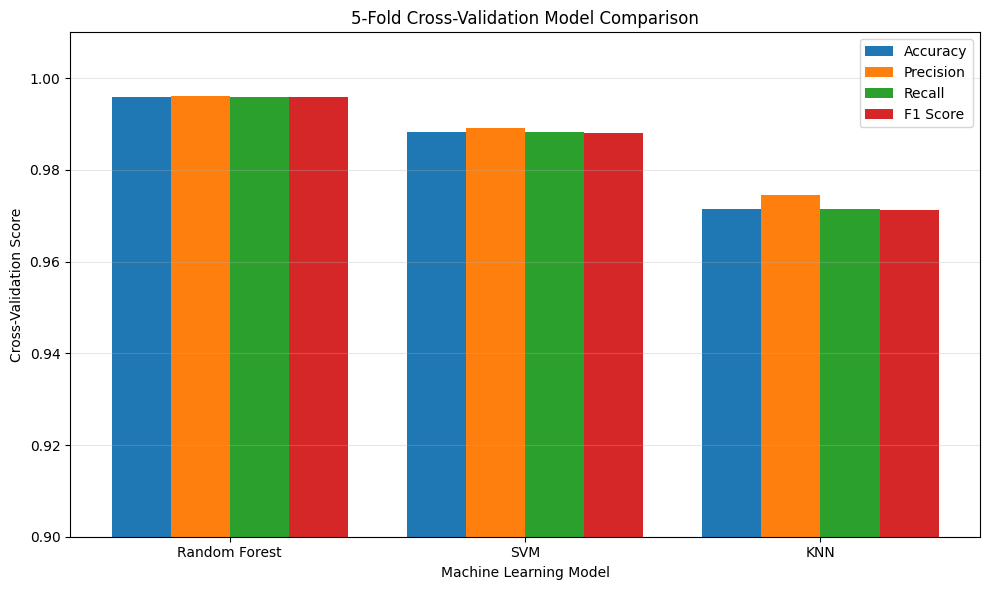

In [19]:
# ============================================
# 5-FOLD CROSS-VALIDATION GRAPH
# ============================================

plt.figure(figsize=(10, 6))

x = np.arange(len(cv_df["Model"]))
width = 0.2

metrics = [
    ("Accuracy", "Accuracy"),
    ("Precision", "Precision"),
    ("Recall", "Recall"),
    ("F1 Score", "F1 Score")
]

for i, (column, label) in enumerate(metrics):

    plt.bar(
        x + (i - 1.5) * width,
        cv_df[column],
        width,
        label=label
    )

plt.xticks(
    x,
    cv_df["Model"]
)

plt.xlabel("Machine Learning Model")
plt.ylabel("Cross-Validation Score")
plt.title("5-Fold Cross-Validation Model Comparison")

plt.ylim(0.90, 1.01)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

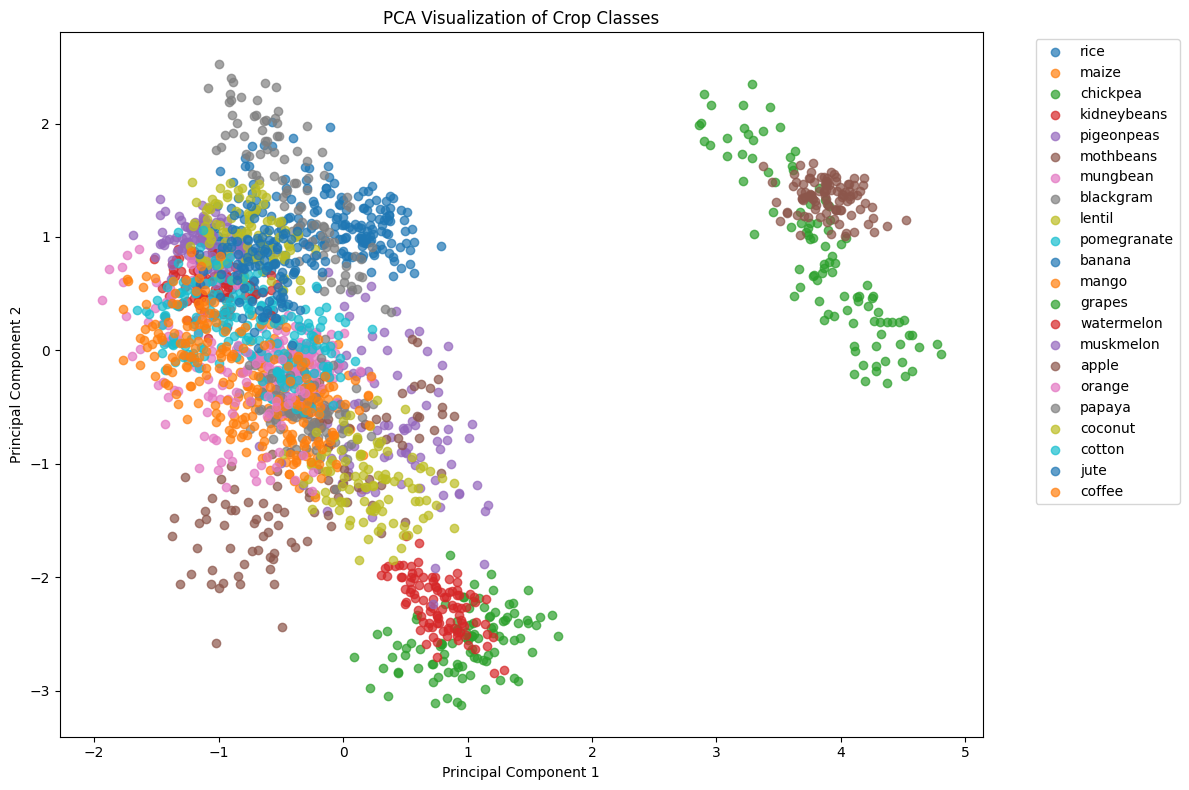

Variance explained by PC1: 27.59 %
Variance explained by PC2: 18.48 %
Total variance explained: 46.07 %


In [20]:
# ============================================
# STEP 3: FEATURE SEPARABILITY
# ============================================

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Reduce 7 dimensions to 2
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Crop": y.values
})

plt.figure(figsize=(12, 8))

for crop in pca_df["Crop"].unique():

    subset = pca_df[pca_df["Crop"] == crop]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=crop,
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Crop Classes")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

print(
    "Variance explained by PC1:",
    round(pca.explained_variance_ratio_[0] * 100, 2),
    "%"
)

print(
    "Variance explained by PC2:",
    round(pca.explained_variance_ratio_[1] * 100, 2),
    "%"
)

print(
    "Total variance explained:",
    round(
        sum(pca.explained_variance_ratio_) * 100,
        2
    ),
    "%"
)